# Where Does the NBA Split? Visualizing the East–West Conference Divide with an SVM

The NBA assigns its 30 teams to an Eastern and a Western conference, ostensibly by geography.
But geography is messy: Memphis sits on the east bank of the Mississippi yet plays in the West,
and the league has redrawn the line after every relocation and expansion.

This notebook treats the conference split as a binary classification problem:

- **Features:** each team's arena location (longitude, latitude)
- **Label:** conference (East / West)
- **Model:** a linear support vector machine — the maximum-margin separator is exactly the
  "fairest" straight line you could draw between the two conferences
- **Output:** the SVM's decision boundary projected onto a map of North America


In [1]:
import urllib.request
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from shapely.geometry import box
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

## The data

`data/arenas.csv` is a hand-curated table of all 30 NBA arenas (2025–26 season) with
their coordinates. Longitude is negative because all of these are west of Greenwich.

In [2]:
arenas = pd.read_csv("../data/arenas.csv")
assert len(arenas) == 30 and arenas["conference"].value_counts().eq(15).all()
arenas.sort_values("lon").head(8)

,team,conference,arena,city,lat,lon
26,Portland Trail Blazers,West,Moda Center,Portland,45.5316,-122.6668
17,Golden State Warriors,West,Chase Center,San Francisco,37.7680,-122.3877
27,Sacramento Kings,West,Golden 1 Center,Sacramento,38.5802,-121.4997
19,LA Clippers,West,Intuit Dome,Los Angeles,33.9450,-118.3417
20,Los Angeles Lakers,West,Crypto.com Arena,Los Angeles,34.0430,-118.2673
25,Phoenix Suns,West,Mortgage Matchup Center,Phoenix,33.4457,-112.0712
29,Utah Jazz,West,Delta Center,Salt Lake City,40.7683,-111.9011
16,Denver Nuggets,West,Ball Arena,Denver,39.7487,-105.0077


## A basemap of North America

We pull country and state/province boundaries from [Natural Earth](https://www.naturalearthdata.com/)
(public domain, 1:110m scale) and cache them in `data/naturalearth/` so the download only happens once.

In [3]:
NE_BASE = "https://naciscdn.org/naturalearth/110m/cultural"
NE_CACHE = Path("../data/naturalearth")


def fetch_naturalearth(layer: str) -> gpd.GeoDataFrame:
    NE_CACHE.mkdir(parents=True, exist_ok=True)
    path = NE_CACHE / f"{layer}.zip"
    if not path.exists():
        urllib.request.urlretrieve(f"{NE_BASE}/{layer}.zip", path)
    return gpd.read_file(path)


countries = fetch_naturalearth("ne_110m_admin_0_countries")
states = fetch_naturalearth("ne_110m_admin_1_states_provinces")

# Map window: covers every arena from Miami (25.8°N) to Portland/Toronto, with breathing room.
XLIM, YLIM = (-128, -64), (22, 53)


def plot_basemap(ax, land=True):
    if land:
        countries.plot(ax=ax, facecolor="0.95", edgecolor="none", zorder=0)
    countries.boundary.plot(ax=ax, color="0.4", linewidth=0.8, zorder=2)
    states.boundary.plot(ax=ax, color="0.6", linewidth=0.3, zorder=2)
    ax.set_xlim(XLIM)
    ax.set_ylim(YLIM)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

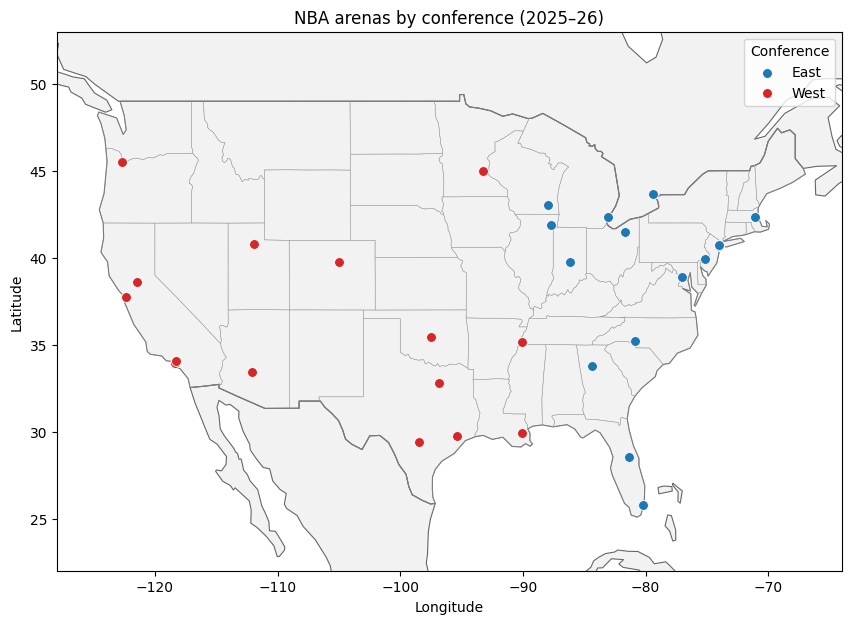

In [4]:
COLORS = {"East": "#1f77b4", "West": "#d62728"}

fig, ax = plt.subplots(figsize=(12, 7))
plot_basemap(ax)
for conf, group in arenas.groupby("conference"):
    ax.scatter(group["lon"], group["lat"], color=COLORS[conf], label=conf,
               s=50, zorder=3, edgecolor="white", linewidth=0.6)
ax.legend(title="Conference")
ax.set_title("NBA arenas by conference (2025–26)")
plt.show()

## Fitting the SVM

A linear SVM finds the separating line that maximizes the margin — the distance to the
closest points on either side. Those closest points are the *support vectors*: they alone
determine where the boundary sits, so for us they are literally the border teams of each conference.

We standardize the features inside a pipeline (longitude spans ~50°, latitude ~20°, and SVMs
are scale-sensitive) and use a large `C` since we expect the conferences to be cleanly separable.

In [5]:
X = arenas[["lon", "lat"]]
y = arenas["conference"]

model = make_pipeline(StandardScaler(), SVC(kernel="linear", C=10))
model.fit(X, y)
svc = model.named_steps["svc"]

print(f"Training accuracy: {model.score(X, y):.0%}")
print(f"Support vectors: {len(svc.support_)} of {len(arenas)} teams")
arenas.iloc[svc.support_][["team", "conference", "city", "lon"]]

Training accuracy: 100%
Support vectors: 5 of 30 teams


,team,conference,city,lon
0,Atlanta Hawks,East,Atlanta,-84.3963
4,Chicago Bulls,East,Chicago,-87.6742
9,Milwaukee Bucks,East,Milwaukee,-87.9172
21,Memphis Grizzlies,West,Memphis,-90.0506
22,Minnesota Timberwolves,West,Minneapolis,-93.2761


## The decision boundary, on the map

`DecisionBoundaryDisplay` evaluates the fitted pipeline on a grid; we lay its shaded regions
under the basemap, draw the boundary (solid) and the margins (dashed), and circle the support vectors.

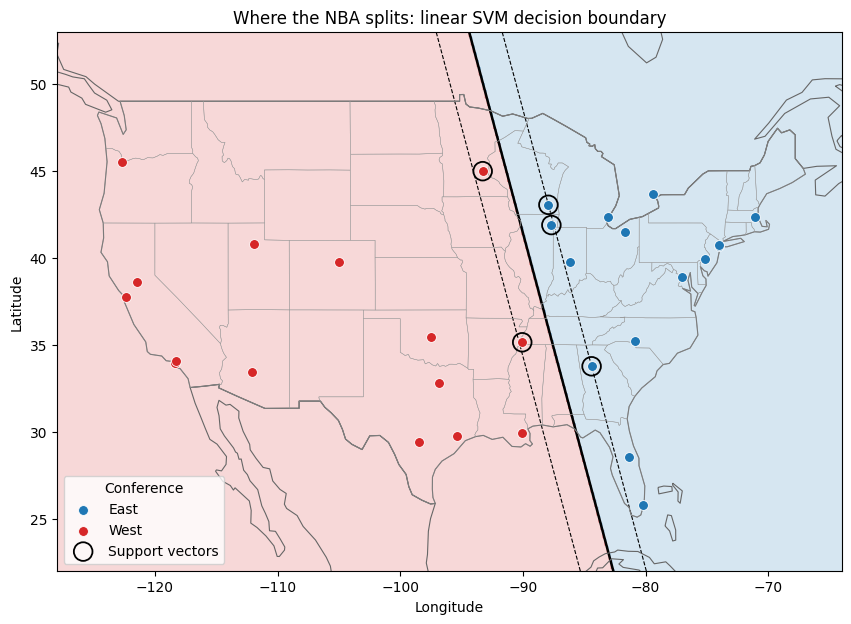

In [6]:
fig, ax = plt.subplots(figsize=(12, 7))

# Two corner points spanning the map window, so the display's grid covers the whole map
# (it derives its range from X) while keeping the column names the pipeline was fit with.
X_extent = pd.DataFrame({"lon": XLIM, "lat": YLIM})

DecisionBoundaryDisplay.from_estimator(
    model, X_extent, response_method="predict", plot_method="contourf",
    cmap=ListedColormap([COLORS[c] for c in svc.classes_]), alpha=0.18,
    grid_resolution=400, ax=ax,
)
DecisionBoundaryDisplay.from_estimator(
    model, X_extent, response_method="decision_function", plot_method="contour",
    levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"],
    linewidths=[0.8, 1.8, 0.8], grid_resolution=400, ax=ax,
)

plot_basemap(ax, land=False)
for conf, group in arenas.groupby("conference"):
    ax.scatter(group["lon"], group["lat"], color=COLORS[conf], label=conf,
               s=50, zorder=3, edgecolor="white", linewidth=0.6)
ax.scatter(X.iloc[svc.support_]["lon"], X.iloc[svc.support_]["lat"],
           facecolor="none", edgecolor="black", s=180, linewidth=1.3,
           zorder=4, label="Support vectors")
ax.legend(title="Conference", loc="lower left")
ax.set_title("Where the NBA splits: linear SVM decision boundary")
plt.show()

## Takeaways

- The conferences are **linearly separable**: a single straight line classifies all 30 teams
  correctly, running near 89°W — roughly down the Mississippi.
- Five teams are support vectors, the literal border of each conference: Memphis and
  Minnesota pressing from the West; Milwaukee, Chicago, and Atlanta from the East.
- The boundary is *not* perfectly vertical: it leans westward as you go north, pinched
  between Atlanta and Memphis (~35°N) at the bottom and between Milwaukee and Minneapolis
  (~44°N) at the top. The margin is only a couple of degrees of longitude wide.

## Beyond the boundary: how lopsided is the split, really?

Look at that map again — a huge share of the country is shaded red. The fitted model gives us a
precise way to quantify the imbalance: classify every point in the lower 48 and tally what falls
on each side. We sample a 10 km grid in an equal-area projection (Albers, so every sample
represents the same amount of land) and let the SVM vote:

In [7]:
usa = countries.loc[countries["ADMIN"] == "United States of America", "geometry"].iloc[0]
conus = usa.intersection(box(-125, 24, -66.5, 49.5))  # lower 48 only

conus_aea = gpd.GeoSeries([conus], crs=4326).to_crs(5070).iloc[0]  # Albers equal-area, meters
xmin, ymin, xmax, ymax = conus_aea.bounds
step = 10_000  # one sample per 10 km x 10 km cell
xx, yy = np.meshgrid(np.arange(xmin, xmax, step), np.arange(ymin, ymax, step))
grid = gpd.GeoSeries(gpd.points_from_xy(xx.ravel(), yy.ravel()), crs=5070)
grid = grid[grid.within(conus_aea)]

lonlat = grid.to_crs(4326)
side = pd.Series(model.predict(pd.DataFrame({"lon": lonlat.x, "lat": lonlat.y})))
total_km2 = len(grid) * (step / 1000) ** 2
for conf, share in side.value_counts(normalize=True).items():
    print(f"{conf}: {share:.1%} of the lower 48 (~{share * total_km2:,.0f} km²)")

West: 73.5% of the lower 48 (~5,866,300 km²)
East: 26.5% of the lower 48 (~2,119,200 km²)


Land is one thing — people are another. `data/state_population_2020.csv` holds official 2020
Census counts for the lower 48 states plus DC. Assigning each whole state to whichever side of
the boundary its interior point falls on (an approximation — a few states straddle the line)
flips the picture:

In [8]:
state_pop = pd.read_csv("../data/state_population_2020.csv")
us_states = states.merge(state_pop, left_on="name", right_on="state")
pts = us_states.geometry.representative_point()
us_states["side"] = model.predict(pd.DataFrame({"lon": pts.x, "lat": pts.y}))

pop_split = us_states.groupby("side")["population"].sum()
for conf, pop in pop_split.items():
    print(f"{conf}: {pop / pop_split.sum():.1%} of the population ({pop:,} people)")
print("\nWest-side states:", ", ".join(sorted(us_states.loc[us_states["side"] == "West", "name"])))

East: 51.5% of the population (169,671,583 people)
West: 48.5% of the population (159,589,036 people)

West-side states: Alabama, Arizona, Arkansas, California, Colorado, Idaho, Illinois, Iowa, Kansas, Louisiana, Minnesota, Mississippi, Missouri, Montana, Nebraska, Nevada, New Mexico, North Dakota, Oklahoma, Oregon, South Dakota, Texas, Utah, Washington, Wyoming


Two more, since the data is cheap. `data/nba_champions.csv` lists every NBA champion
(1947–2025) with the franchise that owns the title today, so we can count rings by *current*
conference — with the caveat that, e.g., the Warriors' 1947 and 1956 titles were won in
Philadelphia. After that: the average great-circle distance between conference rivals — the
West's eternal travel complaint, quantified.

In [9]:
champs = pd.read_csv("../data/nba_champions.csv")
champs = champs.merge(arenas[["team", "conference"]], left_on="franchise", right_on="team", how="left")
champs["conference"] = champs["conference"].fillna("(defunct franchise)")
print(champs["conference"].value_counts().to_string())
champs.groupby(["franchise", "conference"]).size().sort_values(ascending=False).head(6)

conference
East                   41
West                   37
(defunct franchise)     1


franchise              conference
Boston Celtics         East          18
Los Angeles Lakers     West          17
Golden State Warriors  West           7
Chicago Bulls          East           6
San Antonio Spurs      West           5
Detroit Pistons        East           3
dtype: int64

In [10]:
EARTH_R_KM = 6371


def mean_rival_distance(g):
    lat, lon = np.radians(g["lat"].to_numpy()), np.radians(g["lon"].to_numpy())
    h = (np.sin((lat[:, None] - lat) / 2) ** 2
         + np.cos(lat[:, None]) * np.cos(lat) * np.sin((lon[:, None] - lon) / 2) ** 2)
    d = 2 * EARTH_R_KM * np.arcsin(np.sqrt(h))
    return d[np.triu_indices_from(d, k=1)].mean()


for conf, g in arenas.groupby("conference"):
    print(f"{conf}: a conference rival is {mean_rival_distance(g):,.0f} km away on average")

East: a conference rival is 928 km away on average
West: a conference rival is 1,564 km away on average


## Experiment: what if Seattle and Las Vegas joined the league?

Suppose the league expands to 32 teams with the **Seattle SuperSonics** (Climate Pledge Arena)
and a **Las Vegas** franchise (T-Mobile Arena). Both are unambiguously Western, making it 17–15 —
so exactly one current West team must move East to rebalance at 16–16. Which one?

First, a baseline: which teams does the *current* model consider borderline? Distance to the
decision boundary is a natural "contentiousness" score — and NBA fans already argue about
whether Minnesota really belongs in the West.

In [11]:
scores = model.decision_function(X)  # signed distance: positive = West side of the line
contentious = arenas.assign(boundary_dist=np.abs(scores)).sort_values("boundary_dist")
contentious[["team", "conference", "boundary_dist"]].head(5)

,team,conference,boundary_dist
22,Minnesota Timberwolves,West,0.718935
21,Memphis Grizzlies,West,0.906685
4,Chicago Bulls,East,0.926269
0,Atlanta Hawks,East,1.000000
9,Milwaukee Bucks,East,1.000001


Sure enough, Minnesota hugs the line more closely than any team in the league.

Now add the two expansion teams and audition the three plausible movers. For each candidate we
refit with a hard margin (`C=1e6` — *insist* on a line that separates perfectly) and compare
margin widths, the SVM's measure of how comfortable the new split is:

In [12]:
expansion = pd.DataFrame([
    {"team": "Seattle SuperSonics", "conference": "West", "arena": "Climate Pledge Arena",
     "city": "Seattle", "lat": 47.6221, "lon": -122.3540},
    {"team": "Las Vegas (expansion)", "conference": "West", "arena": "T-Mobile Arena",
     "city": "Las Vegas", "lat": 36.1029, "lon": -115.1784},
])
league32 = pd.concat([arenas, expansion], ignore_index=True)


def fit_hard(df):
    pipe = make_pipeline(StandardScaler(), SVC(kernel="linear", C=1e6))
    pipe.fit(df[["lon", "lat"]], df["conference"])
    return pipe


for mover in ["Minnesota Timberwolves", "Memphis Grizzlies", "New Orleans Pelicans"]:
    trial = league32.copy()
    trial.loc[trial["team"] == mover, "conference"] = "East"
    pipe = fit_hard(trial)
    width = 2 / np.linalg.norm(pipe.named_steps["svc"].coef_)
    print(f"{mover:23s} -> East: margin width {width:.3f} (standardized units)")

Minnesota Timberwolves  -> East: margin width 0.205 (standardized units)
Memphis Grizzlies       -> East: margin width 0.068 (standardized units)
New Orleans Pelicans    -> East: margin width 0.050 (standardized units)


The Timberwolves win by a factor of 3–4: moving Memphis or New Orleans instead would force the
line through the ~0.03° of longitude between those two arenas. So the SVM agrees with the fans —
when the West gets crowded, Minnesota is the team to flip. The new boundary stops being a
Mississippi line and becomes a hard diagonal from the Prairies to the Gulf:

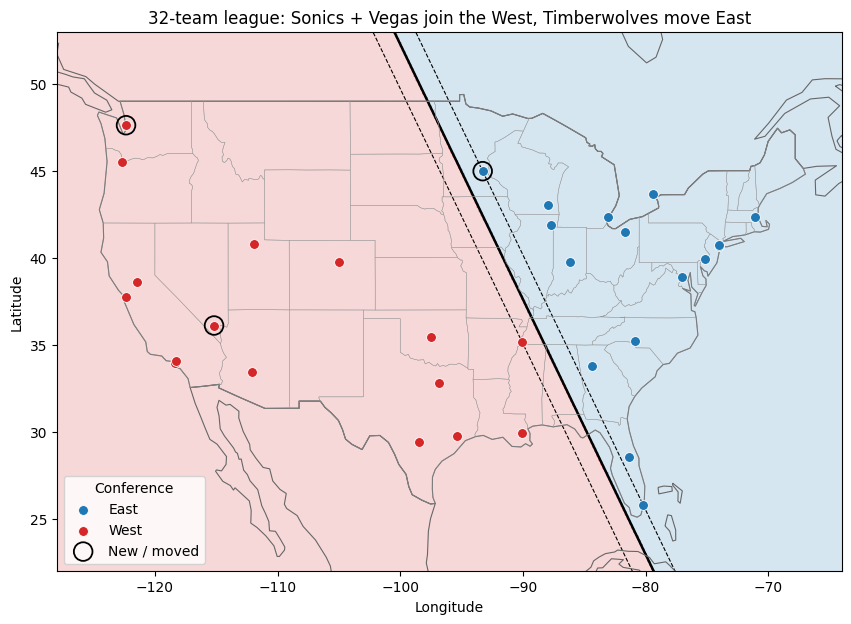

In [13]:
league32_final = league32.copy()
league32_final.loc[league32_final["team"] == "Minnesota Timberwolves", "conference"] = "East"
model32 = fit_hard(league32_final)
svc32 = model32.named_steps["svc"]

fig, ax = plt.subplots(figsize=(12, 7))
DecisionBoundaryDisplay.from_estimator(
    model32, X_extent, response_method="predict", plot_method="contourf",
    cmap=ListedColormap([COLORS[c] for c in svc32.classes_]), alpha=0.18,
    grid_resolution=400, ax=ax,
)
DecisionBoundaryDisplay.from_estimator(
    model32, X_extent, response_method="decision_function", plot_method="contour",
    levels=[-1, 0, 1], colors="black", linestyles=["--", "-", "--"],
    linewidths=[0.8, 1.8, 0.8], grid_resolution=400, ax=ax,
)
plot_basemap(ax, land=False)
for conf, group in league32_final.groupby("conference"):
    ax.scatter(group["lon"], group["lat"], color=COLORS[conf], label=conf,
               s=50, zorder=3, edgecolor="white", linewidth=0.6)
changed = league32_final["team"].isin(expansion["team"].tolist() + ["Minnesota Timberwolves"])
ax.scatter(league32_final.loc[changed, "lon"], league32_final.loc[changed, "lat"],
           facecolor="none", edgecolor="black", s=180, linewidth=1.3,
           zorder=4, label="New / moved")
ax.legend(title="Conference", loc="lower left")
ax.set_title("32-team league: Sonics + Vegas join the West, Timberwolves move East")
plt.show()

## Do fancier kernels change the answer?

Two upgrades a skeptic might demand, and what they're for:

1. **RBF kernel** — the linear SVM can only draw straight lines; the RBF (radial basis
   function) kernel lets the boundary curve and wrap around clusters. If the conferences
   weren't separable by a line, this is what you'd reach for.
2. **Great-circle distances** — treating lon/lat as flat x/y distorts geometry (a degree of
   longitude shrinks as you go north). An SVM with a *precomputed* kernel can work directly
   from true over-the-curve distances between arenas instead of coordinates.

The data is linearly separable, so the prediction is that neither buys anything — same split,
more machinery. Let's check:

In [14]:
# RBF: same pipeline as the linear model, curvier kernel.
rbf_model = make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10))
rbf_model.fit(X, y)

# Great-circle: hand the SVM a Gaussian kernel built on real over-the-curve distances.
X_np = X.to_numpy()  # columns: lon, lat


def haversine_matrix(A, B):
    lat1, lon1 = np.radians(A[:, 1]), np.radians(A[:, 0])
    lat2, lon2 = np.radians(B[:, 1]), np.radians(B[:, 0])
    h = (np.sin((lat1[:, None] - lat2) / 2) ** 2
         + np.cos(lat1[:, None]) * np.cos(lat2) * np.sin((lon1[:, None] - lon2) / 2) ** 2)
    return 2 * EARTH_R_KM * np.arcsin(np.sqrt(h))


SIGMA_KM = 1500  # kernel length scale, on the order of inter-team distances
K_train = np.exp(-haversine_matrix(X_np, X_np) ** 2 / (2 * SIGMA_KM**2))
gc_svc = SVC(kernel="precomputed", C=10).fit(K_train, y)

kx, ky = np.meshgrid(np.linspace(*XLIM, 300), np.linspace(*YLIM, 300))
grid_kernels = pd.DataFrame({"lon": kx.ravel(), "lat": ky.ravel()})

print(f"Linear:        accuracy {model.score(X, y):.0%}, support vectors {len(svc.support_)}")
print(f"RBF:           accuracy {rbf_model.score(X, y):.0%}, "
      f"support vectors {len(rbf_model.named_steps['svc'].support_)}")
print(f"Great-circle:  accuracy {gc_svc.score(K_train, y):.0%}, support vectors {len(gc_svc.support_)}")

Linear:        accuracy 100%, support vectors 5
RBF:           accuracy 100%, support vectors 7
Great-circle:  accuracy 100%, support vectors 7


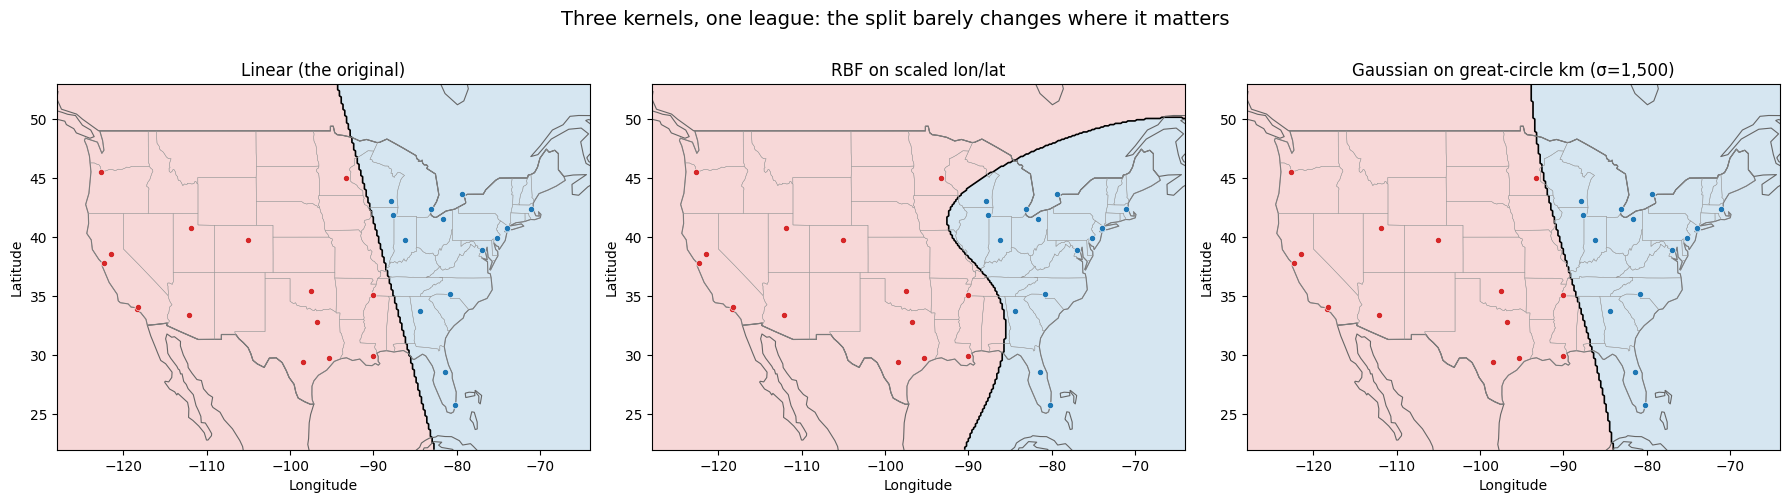

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
kernel_preds = {
    "Linear (the original)": model.predict(grid_kernels),
    "RBF on scaled lon/lat": rbf_model.predict(grid_kernels),
    f"Gaussian on great-circle km (σ={SIGMA_KM:,.0f})": gc_svc.predict(
        np.exp(-haversine_matrix(grid_kernels.to_numpy(), X_np) ** 2 / (2 * SIGMA_KM**2))
    ),
}
for ax, (title, pred) in zip(axes, kernel_preds.items()):
    z = (pred == "West").reshape(kx.shape)
    ax.contourf(kx, ky, z, levels=[-0.5, 0.5, 1.5],
                cmap=ListedColormap([COLORS["East"], COLORS["West"]]), alpha=0.18)
    ax.contour(kx, ky, z, levels=[0.5], colors="black", linewidths=1.2)
    plot_basemap(ax, land=False)
    for conf, group in arenas.groupby("conference"):
        ax.scatter(group["lon"], group["lat"], color=COLORS[conf], s=20, zorder=3,
                   edgecolor="white", linewidth=0.4)
    ax.set_title(title)
fig.suptitle("Three kernels, one league: the split barely changes where it matters", fontsize=14)
fig.tight_layout()
plt.show()

All three classifiers are perfect on the training data, and near the arenas they agree almost
everywhere — the extra flexibility of the curved kernels buys nothing on separable data; it
just spends more support vectors. The boundaries only diverge far from any team, where the
models are unconstrained and the shading is essentially arbitrary. That's the general lesson:
**model complexity should be earned by the data, and 30 cleanly-separable points earn none.**

## How the line has drifted: league maps since 1980

The league redrew itself many times — relocations, expansion waves, two Canadian franchises.
`data/arenas_historical.csv` holds hand-curated snapshots at the major turning points (per the
franchises' relocation histories), each with the arena the team actually played in that season:

- **1980–81** (23 teams) — the first season of the modern conference alignment: the Spurs and
  Bucks settle into West and East, Kings still in Kansas City, Clippers in San Diego.
- **1990–91** (27 teams) — after the late-80s expansion wave (Heat, Hornets, Magic, Wolves).
- **2000–01** (29 teams) — Grizzlies in *Vancouver*, Hornets in Charlotte, Sonics in Seattle.
- **2010–11** (30 teams) — the Thunder era begins; Hornets now in New Orleans.

We refit the hard-margin SVM on each snapshot and watch the fairest line move:

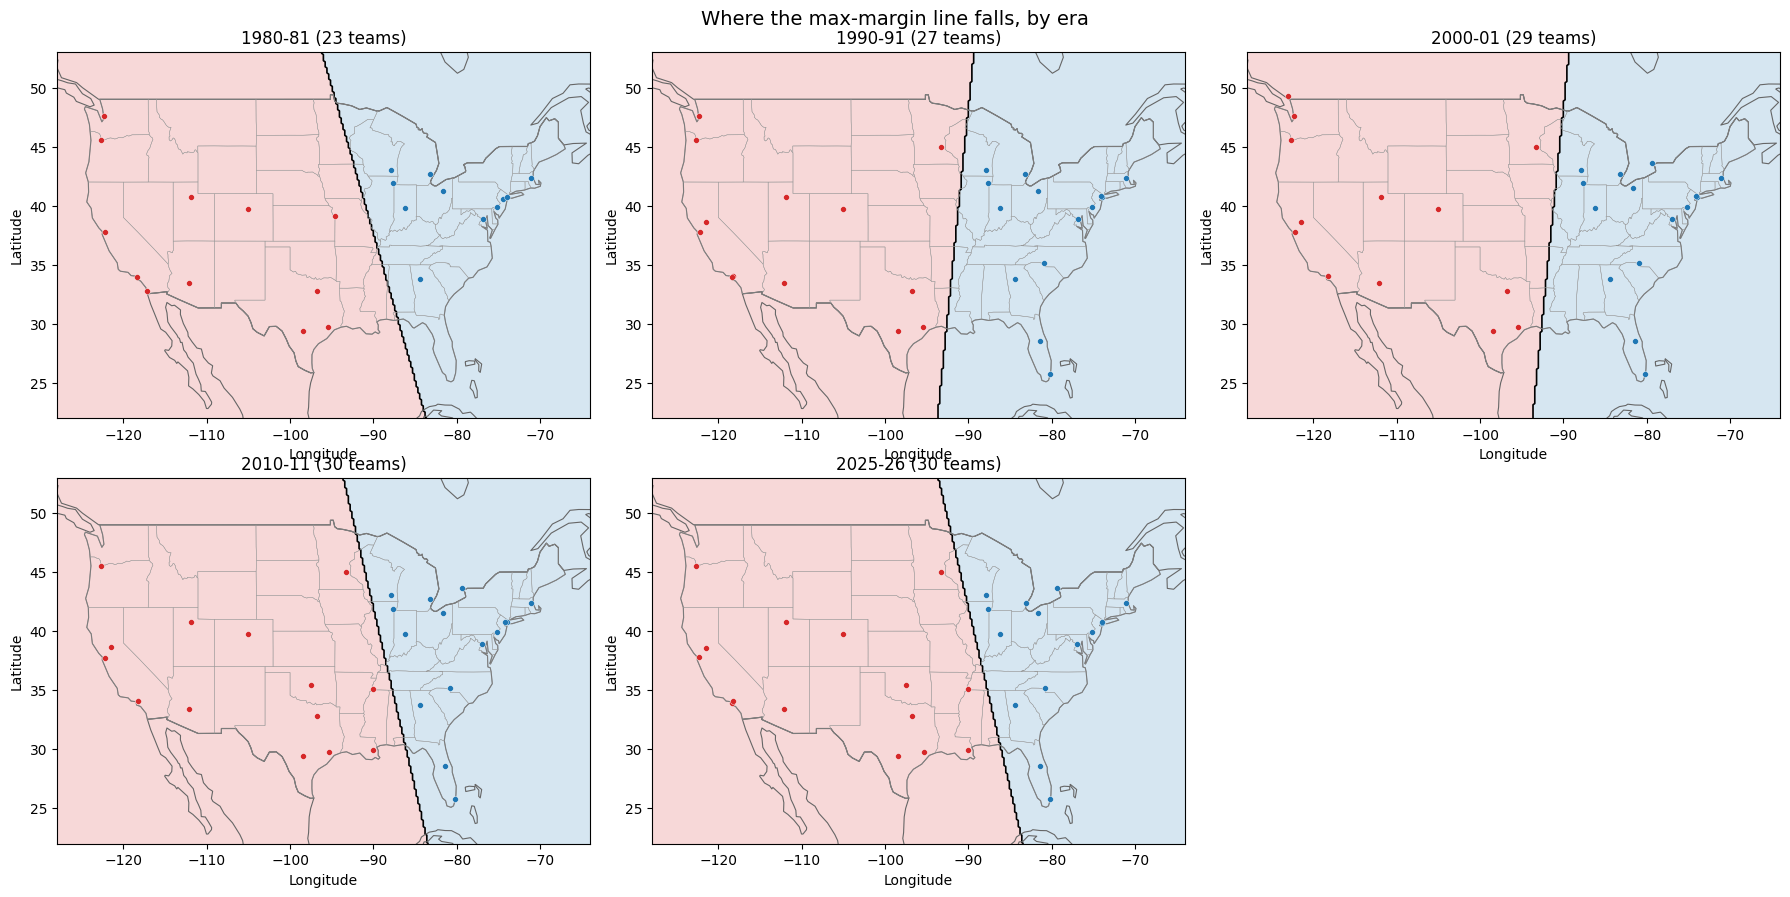

In [16]:
hist = pd.read_csv("../data/arenas_historical.csv")
eras = pd.concat([hist, arenas.assign(season="2025-26")], ignore_index=True)

gx, gy = np.meshgrid(np.linspace(*XLIM, 300), np.linspace(*YLIM, 300))
grid_df = pd.DataFrame({"lon": gx.ravel(), "lat": gy.ravel()})
era_cmap = ListedColormap([COLORS["East"], COLORS["West"]])

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, season in zip(axes.ravel(), ["1980-81", "1990-91", "2000-01", "2010-11", "2025-26"]):
    league = eras[eras["season"] == season]
    era_model = fit_hard(league)
    z = (era_model.predict(grid_df) == "West").reshape(gx.shape)
    ax.contourf(gx, gy, z, levels=[-0.5, 0.5, 1.5], cmap=era_cmap, alpha=0.18)
    ax.contour(gx, gy, z, levels=[0.5], colors="black", linewidths=1.2)
    plot_basemap(ax, land=False)
    for conf, group in league.groupby("conference"):
        ax.scatter(group["lon"], group["lat"], color=COLORS[conf], s=18, zorder=3,
                   edgecolor="white", linewidth=0.3)
    ax.set_title(f"{season} ({len(league)} teams)")
axes.ravel()[-1].set_axis_off()
fig.suptitle("Where the max-margin line falls, by era", fontsize=14)
fig.tight_layout()
plt.show()

The story across 45 years: through the 80s and 90s the nearest West team to the line was in
Texas or Kansas City, leaving a margin several degrees of longitude wide. The 1989 arrival of
Minnesota narrowed it, and the Grizzlies' 2001 move from Vancouver to Memphis — plus the
Hornets landing in New Orleans — dragged the West's eastern frontier to the Mississippi,
collapsing the margin to the sliver we see today. The fairest line between the conferences
has been drifting **east** for half a century.

A wrinkle worth knowing from the expansion experiment: at the softer `C=10` used in the main
analysis, the SVM would rather *misclassify Memphis* than accept a cramped line — in all three
rebalancing scenarios. Expansion genuinely makes Memphis geographically incoherent.

### Ideas to extend

- More conference facts: average elevation (needs a terrain raster, e.g. ETOPO/USGS) and median
  household income (Census ACS) per decision region. Team popularity would need a defensible
  proxy (Google Trends, merchandise sales) — no official source exists.
- A smooth per-season animation of the drifting boundary — the website version of the era maps
  above, which needs the historical dataset filled in season by season.